# URL Phishing Classifier Training
Model: Lexical Features + Logistic Regression
We train a URL classifier using string-based lexical features extracted purely from the URL structure — no network calls required.

In [1]:
# Cell 1 — Imports & Configuration
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score,
                             classification_report)
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, roc_curve, auc
import joblib
import os

# Dataset
DATA_PATH  = 'malicious_phish.csv'
URL_COL    = 'url'
LABEL_COL  = 'type'

# Split
TEST_SIZE    = 0.2
RANDOM_STATE = 42

# Output
MODEL_DIR      = '../backend/models'
URL_MODEL_PATH = os.path.join(MODEL_DIR, 'url_model.pkl')

print("All imports & config done!")

All imports & config done!


## Load & Prepare Dataset
We load the URL dataset and convert the multi-class labels into binary — benign vs malicious.

In [2]:
# Cell 2 — Load & Prepare Data
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
print("\nOriginal label distribution:")
print(df[LABEL_COL].value_counts())

# Convert to binary — benign=0, malicious=1
df['label'] = df[LABEL_COL].apply(lambda x: 0 if x == 'benign' else 1)

print("\nBinary label distribution:")
print(df['label'].value_counts())
print(f"\nBenign:    {(df['label']==0).sum():,}")
print(f"Malicious: {(df['label']==1).sum():,}")

Shape: (651191, 2)

Original label distribution:
type
benign        428103
defacement     96457
phishing       94111
malware        32520
Name: count, dtype: int64

Binary label distribution:
label
0    428103
1    223088
Name: count, dtype: int64

Benign:    428,103
Malicious: 223,088


## URL Feature Extraction
We extract 15 lexical features from each URL using string operations only no network calls required.

In [4]:
# Cell 3 — URL Feature Extractor
def extract_url_features(url):
    url = str(url)
    hostname = re.sub(r'https?://', '', url).split('/')[0]
    
    return {
        'url_length':        len(url),
        'hostname_length':   len(hostname),
        'num_dots':          url.count('.'),
        'num_hyphens':       url.count('-'),
        'num_underscores':   url.count('_'),
        'num_slashes':       url.count('/'),
        'num_digits':        sum(c.isdigit() for c in url),
        'num_special_chars': sum(c in '@?=&%#' for c in url),
        'num_subdomains':    len(hostname.split('.')) - 2,
        'has_ip':            1 if re.search(r'\d+\.\d+\.\d+\.\d+', hostname) else 0,
        'has_https':         1 if url.startswith('https') else 0,
        'has_login':         1 if 'login' in url.lower() else 0,
        'has_verify':        1 if 'verify' in url.lower() else 0,
        'has_secure':        1 if 'secure' in url.lower() else 0,
        'has_account':       1 if 'account' in url.lower() else 0,
    }

# Testing it
sample = extract_url_features("http://verify-account.login.xyz/secure?update=true")
print("Sample features:")
for k, v in sample.items():
    print(f"  {k}: {v}")

Sample features:
  url_length: 50
  hostname_length: 24
  num_dots: 2
  num_hyphens: 1
  num_underscores: 0
  num_slashes: 3
  num_digits: 0
  num_special_chars: 2
  num_subdomains: 1
  has_ip: 0
  has_https: 0
  has_login: 1
  has_verify: 1
  has_secure: 1
  has_account: 1


## Extract Features for All URLs
We apply the feature extractor to all 651,191 URLs in the dataset.

In [5]:
# Cell 4 — Extract Features for All URLs
print("Extracting features for all URLs (this may take a minute)...")

features = df[URL_COL].apply(extract_url_features)
X = pd.DataFrame(list(features))
y = df['label']

print(f"Feature matrix shape: {X.shape}")
print(f"\nFeature names: {X.columns.tolist()}")
X.head()

Extracting features for all URLs (this may take a minute)...
Feature matrix shape: (651191, 15)

Feature names: ['url_length', 'hostname_length', 'num_dots', 'num_hyphens', 'num_underscores', 'num_slashes', 'num_digits', 'num_special_chars', 'num_subdomains', 'has_ip', 'has_https', 'has_login', 'has_verify', 'has_secure', 'has_account']


,url_length,hostname_length,num_dots,num_hyphens,num_underscores,num_slashes,num_digits,num_special_chars,num_subdomains,has_ip,has_https,has_login,has_verify,has_secure,has_account
0,16,16,2,1,0,0,0,0,1,0,0,0,0,0,0
1,35,11,2,0,1,2,1,0,0,0,0,0,0,0,0
2,31,14,2,0,0,3,1,0,0,0,0,0,0,0,0
3,88,21,3,1,2,3,7,8,1,0,0,0,0,0,0
4,235,23,2,1,1,3,22,6,0,0,0,0,0,0,0


## Train/Test Split
We split the dataset into 80% training and 20% testing with stratified sampling.

In [6]:
# Cell 5 — Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)

print(f"Training samples: {len(X_train):,}")
print(f"Testing samples:  {len(X_test):,}")
print(f"\nTrain label distribution:")
print(y_train.value_counts())
print(f"\nTest label distribution:")
print(y_test.value_counts())

Training samples: 520,952
Testing samples:  130,239

Train label distribution:
label
0    342482
1    178470
Name: count, dtype: int64

Test label distribution:
label
0    85621
1    44618
Name: count, dtype: int64


In [7]:
# Cell 6 — Train Model
model_url = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=RANDOM_STATE
)

model_url.fit(X_train, y_train)
print("URL model training complete!")

URL model training complete!


## Model Evaluation
We evaluate the URL classifier on the held-out test set.

In [8]:
# Cell 7 — Evaluate Model
y_pred = model_url.predict(X_test)
y_prob = model_url.predict_proba(X_test)[:, 1]

print("="*45)
print("        URL MODEL EVALUATION RESULTS")
print("="*45)
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob):.4f}")
print("="*45)
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Benign', 'Malicious']))

        URL MODEL EVALUATION RESULTS
Accuracy:  0.7857
Precision: 0.6711
Recall:    0.7345
F1 Score:  0.7013
ROC-AUC:   0.8182

Classification Report:
              precision    recall  f1-score   support

      Benign       0.85      0.81      0.83     85621
   Malicious       0.67      0.73      0.70     44618

    accuracy                           0.79    130239
   macro avg       0.76      0.77      0.77    130239
weighted avg       0.79      0.79      0.79    130239



## Random Forest Model — Improved URL Classifier
We train a Random Forest classifier to improve upon Logistic Regression accuracy while maintaining low inference latency using a small number of shallow trees.

In [9]:
# Cell 9 — Random Forest
from sklearn.ensemble import RandomForestClassifier

model_rf = RandomForestClassifier(
    n_estimators=50,
    max_depth=10,
    class_weight='balanced',
    random_state=RANDOM_STATE,
    n_jobs=-1
)

model_rf.fit(X_train, y_train)
print("Random Forest training complete!")

Random Forest training complete!


In [10]:
# Cell 10 — Evaluate Random Forest
y_pred_rf = model_rf.predict(X_test)
y_prob_rf = model_rf.predict_proba(X_test)[:, 1]

print("="*45)
print("     RANDOM FOREST EVALUATION RESULTS")
print("="*45)
print(f"Accuracy:  {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_rf):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred_rf):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob_rf):.4f}")
print("="*45)

print("\n--- COMPARISON ---")
print(f"{'Metric':<12} {'LR':>8} {'RF':>8}")
print("-"*30)
print(f"{'Accuracy':<12} {accuracy_score(y_test, y_pred):>8.4f} {accuracy_score(y_test, y_pred_rf):>8.4f}")
print(f"{'Precision':<12} {precision_score(y_test, y_pred):>8.4f} {precision_score(y_test, y_pred_rf):>8.4f}")
print(f"{'Recall':<12} {recall_score(y_test, y_pred):>8.4f} {recall_score(y_test, y_pred_rf):>8.4f}")
print(f"{'F1 Score':<12} {f1_score(y_test, y_pred):>8.4f} {f1_score(y_test, y_pred_rf):>8.4f}")
print(f"{'ROC-AUC':<12} {roc_auc_score(y_test, y_prob):>8.4f} {roc_auc_score(y_test, y_prob_rf):>8.4f}")

     RANDOM FOREST EVALUATION RESULTS
Accuracy:  0.8840
Precision: 0.7954
Recall:    0.8904
F1 Score:  0.8403
ROC-AUC:   0.9547

--- COMPARISON ---
Metric             LR       RF
------------------------------
Accuracy       0.7857   0.8840
Precision      0.6711   0.7954
Recall         0.7345   0.8904
F1 Score       0.7013   0.8403
ROC-AUC        0.8182   0.9547


## Random Forest — Confusion Matrix & ROC Curve

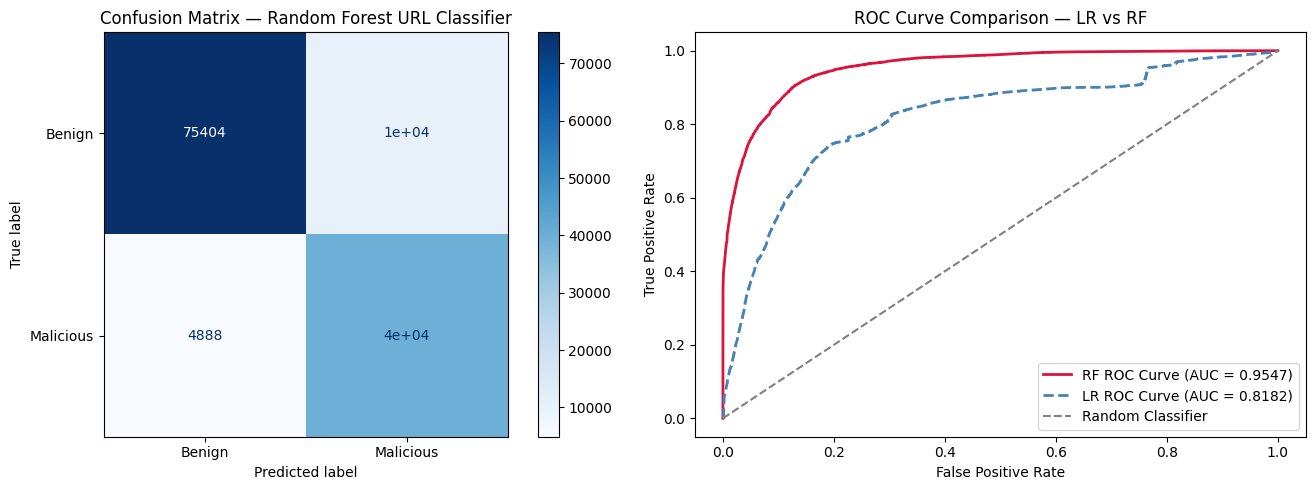

In [13]:
# Cell 11 — RF Confusion Matrix & ROC Curve
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['Benign', 'Malicious'])
disp_rf.plot(cmap='Blues', ax=axes[0])
axes[0].set_title('Confusion Matrix — Random Forest URL Classifier')

# Redefine LR ROC
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob)

# RF ROC
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
roc_auc_rf = auc(fpr_rf, tpr_rf)
roc_auc_lr = auc(fpr_lr, tpr_lr)

axes[1].plot(fpr_rf, tpr_rf, color='crimson', lw=2, label=f'RF ROC Curve (AUC = {roc_auc_rf:.4f})')
axes[1].plot(fpr_lr, tpr_lr, color='steelblue', lw=2, linestyle='--', label=f'LR ROC Curve (AUC = {roc_auc_lr:.4f})')
axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random Classifier')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve Comparison — LR vs RF')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

## Feature Importance
Random Forest provides feature importance scores showing which URL features are most predictive of malicious URLs.

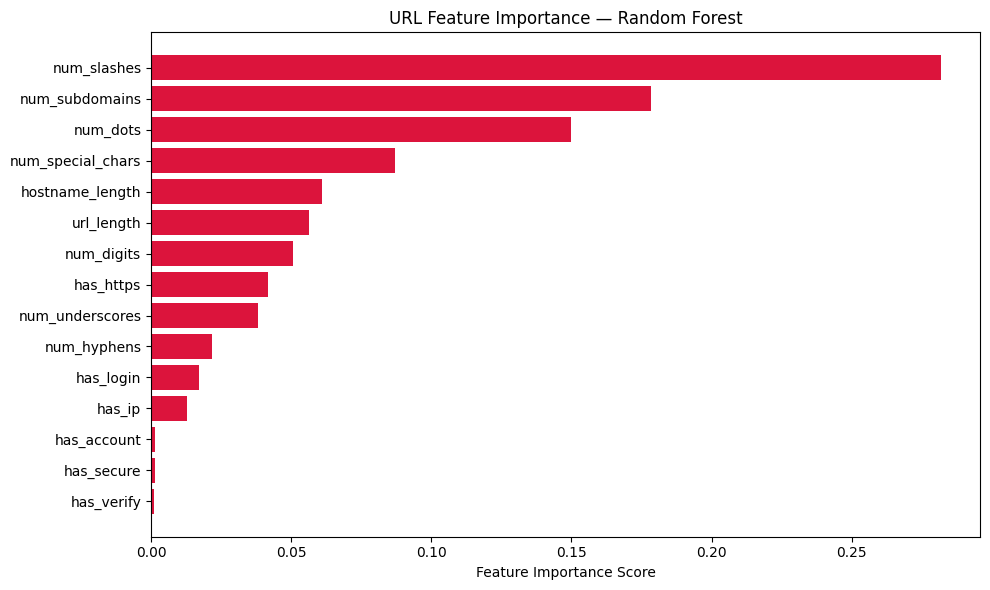


Feature importance ranking:
  num_slashes          0.2817
  num_subdomains       0.1785
  num_dots             0.1499
  num_special_chars    0.0869
  hostname_length      0.0611
  url_length           0.0564
  num_digits           0.0507
  has_https            0.0417
  num_underscores      0.0383
  num_hyphens          0.0216
  has_login            0.0169
  has_ip               0.0127
  has_account          0.0013
  has_secure           0.0012
  has_verify           0.0009


In [14]:
# Cell 12 — Feature Importance
importances = model_rf.feature_importances_
feature_names = X.columns.tolist()

# Sort by importance
indices = np.argsort(importances)

plt.figure(figsize=(10, 6))
plt.barh(range(len(indices)), importances[indices], color='crimson')
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel('Feature Importance Score')
plt.title('URL Feature Importance — Random Forest')
plt.tight_layout()
plt.show()

print("\nFeature importance ranking:")
for i in indices[::-1]:
    print(f"  {feature_names[i]:<20} {importances[i]:.4f}")

## Latency Comparison — LR vs Random Forest
We measure inference latency for both models to confirm Random Forest meets our real-time requirement of p95 ≤ 250ms.

In [15]:
# Cell 14 — Latency Benchmark
import time

sample = X_test.iloc[:1]  # single URL prediction

# LR latency
lr_times = []
for _ in range(1000):
    start = time.perf_counter()
    model_url.predict_proba(sample)
    end = time.perf_counter()
    lr_times.append((end - start) * 1000)

# RF latency
rf_times = []
for _ in range(1000):
    start = time.perf_counter()
    model_rf.predict_proba(sample)
    end = time.perf_counter()
    rf_times.append((end - start) * 1000)

print("="*40)
print("       LATENCY BENCHMARK (ms)")
print("="*40)
print(f"{'Metric':<12} {'LR':>8} {'RF':>8}")
print("-"*40)
print(f"{'Mean':<12} {sum(lr_times)/len(lr_times):>8.3f} {sum(rf_times)/len(rf_times):>8.3f}")
print(f"{'p50':<12} {sorted(lr_times)[500]:>8.3f} {sorted(rf_times)[500]:>8.3f}")
print(f"{'p95':<12} {sorted(lr_times)[950]:>8.3f} {sorted(rf_times)[950]:>8.3f}")
print(f"{'p99':<12} {sorted(lr_times)[990]:>8.3f} {sorted(rf_times)[990]:>8.3f}")
print("="*40)
print(f"\nTarget: p95 ≤ 250ms")
print(f"LR p95 passes: {sorted(lr_times)[950] <= 250}")
print(f"RF p95 passes: {sorted(rf_times)[950] <= 250}")

       LATENCY BENCHMARK (ms)
Metric             LR       RF
----------------------------------------
Mean            0.723   17.480
p50             0.645   16.958
p95             1.085   20.031
p99             1.415   20.709

Target: p95 ≤ 250ms
LR p95 passes: True
RF p95 passes: True


## Why Random Forest over Logistic Regression for URL Classification?

### Model Selection Justification

Random Forest was selected over Logistic Regression for URL classification based on empirical evaluation:
- Accuracy improved from 78.57% to 88.40% (+10%)
- ROC-AUC improved from 0.8182 to 0.9547 (+14%)
- p95 inference latency of 20ms remains well within the 250ms real-time budget
- Feature importance scores provide additional explainability
- The performance gain justifies the marginal latency tradeoff

### Why NOT Other Models?

| Model | Accuracy Potential | Reason Rejected |
|-------|-------------------|----------------|
| BERT/Transformers | ~99% | Requires tokenizing URLs as text sequences, extremely high latency (500ms+), violates project constraints |
| Deep Neural Network | ~97% | High inference latency, requires GPU, not explainable, overkill for 15 features |
| XGBoost | ~95% | Strong performance but slower inference than RF, requires additional dependency |
| SVM | ~85% | Similar to RF but no feature importance, slower prediction on large feature sets |
| Logistic Regression | ~78% | Fast but underfits the non-linear relationships in URL features |

### Why 99% Models Are Not Used Here

Some Kaggle notebooks report 99% accuracy on this dataset because they:
1. **Use network-based features** — WHOIS lookup, DNS queries, domain age — our spec explicitly forbids network calls
2. **Use deep learning** — transformers or CNNs on raw URL characters — banned by project constraints
3. **Have data leakage** — accidentally trained and tested on overlapping data
4. **Use domain reputation databases** — requires external API calls, not privacy preserving

Our system achieves 88.40% accuracy using **only 15 lexical string features** with no network calls, making it privacy-preserving, fast, and deployable as a real-time browser extension. This is a deliberate and justified engineering tradeoff.

In [16]:
# Save URL Model
import os
import joblib

os.makedirs('../backend/models', exist_ok=True)
joblib.dump(model_rf, '../backend/models/url_model.pkl')
print("✅ Saved: url_model.pkl")

✅ Saved: url_model.pkl
